# 01. M2 slice: noise floor and drift (BTCUSDT, h = 8)

First slice of PLAN §13 M2, run after the pre-registration freeze (`prereg-v1`; D-51, D-52):
EBM `interactions=0`, BTCUSDT, h = 8, all 83 rolling 12-month windows, targets direction (`dir`),
normalised forward volatility (`vol`) and the shifted direction control (`shuf`), 5 seed-only + 10
half-sample fits per window and target, plus one stationary surrogate (`surrogate:0`, dir and vol).

Contents: 1. run and compute; 2. noise floor; 3. validity gate G0 and floor diagnosis;
4. drift variogram γ(Δ) (control arms only); 5. positive control; 6. go / no-go.

**G0 and its pre-specified DR* fallback fail (section 3).** PLAN §2 then requires the floor to be fixed
before any real-target drift result is looked at. This notebook therefore shows drift only for the
control arms (shuffled target and surrogates); real-target γ(Δ), DR over time, per-feature DR and the
shape gallery are withheld until the floor is fixed (see DECISIONS D-54).

All numbers come from `results/slice/compare/*.parquet` (written by `ebmregime.runner.compare`) and
the run logs. Definitions: PLAN §6; thresholds: `configs/prereg.yaml`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ebmregime.config import load_config, repo_path
from ebmregime.report import slice as R

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
OUT = repo_path("results/slice")
C = OUT / "compare"
prereg = load_config("prereg")
windows = pd.read_parquet(C / "windows.parquet")
wfeat = pd.read_parquet(C / "window_features.parquet")
pairs = pd.read_parquet(C / "pairs.parquet")
pfeat = pd.read_parquet(C / "pair_features.parquet")
shapes = pd.read_parquet(C / "shapes.parquet")
fits = pd.read_parquet(C / "fits.parquet")
info = json.loads((C / "compare_info.json").read_text())
kill = json.loads((OUT / "kill_resume_trial.json").read_text())
print(f"{len(fits)} fits, {len(windows)} window rows, {len(pairs)} pair rows; compare stage: {info}")

6225 fits, 415 window rows, 2810 pair rows; compare stage: {'grid': 'configs/grid_slice.yaml', 'n_windows': 415, 'n_pairs': 2810, 'seconds_windows': 14.493871688842773, 'seconds_pairs': 141.32985997200012, 'lags': [1, 2, 3, 6, 12, 18, 24, 36]}


## 1. Run and compute (criteria 1 and 4)

In [2]:
print("Kill-and-resume trial (hard kill of the process tree after ~150 s):")
print(json.dumps(kill, indent=1))

t = fits.copy()
t["kind"] = np.where(t["target"] == "vol", "regressor (vol)", "classifier (dir/shuf)")
tab = (t.groupby(["kind", "protocol"])
         .agg(n=("fit_seconds", "size"), fit_s_median=("fit_seconds", "median"), fit_s_mean=("fit_seconds", "mean"),
              rounds_median=("best_iteration_median", "median"), rows_median=("n_rows_fit", "median")))
display(tab.round(2))
plan = {("classifier (dir/shuf)", "seed"): 3.0, ("classifier (dir/shuf)", "half"): 2.2,
        ("regressor (vol)", "seed"): 5.3, ("regressor (vol)", "half"): 5.3 * 2.2 / 3.0}
tab2 = tab[["fit_s_mean"]].copy()
tab2["plan_s (§11.1)"] = [plan[i] for i in tab2.index]
tab2["ratio"] = tab2["fit_s_mean"] / tab2["plan_s (§11.1)"]
display(tab2.round(2))
cpu = float(t["fit_seconds"].sum())
print(f"single-thread fit CPU: {cpu/3600:.2f} h over {len(t)} fits")

Kill-and-resume trial (hard kill of the process tree after ~150 s):
{
 "kill_after_s": 151.1,
 "finished_before_run": 195,
 "finished_at_kill": 467,
 "finished_after_kill": 467,
 "new_fits_this_run": 272,
 "appeared_after_kill_snapshot": 0,
 "vanished_after_kill": 0,
 "on_disk_not_logged_by_parent": 0,
 "worker_processes_at_kill": 19,
 "workers_busy_at_kill": 16,
 "lost_fits_upper_bound": 16,
 "stale_tmp_files": 0,
 "surviving_processes": [],
 "fit_rate_per_min": 108.0
}


n  fit_s_median  fit_s_mean  rounds_median  rows_median
kind                  protocol                                                            
classifier (dir/shuf) half      2490          2.95        3.26        2810.50       4402.0
                      seed      1245          3.60        4.29        2813.00       8678.0
regressor (vol)       half      1660          7.38        7.45        9658.50       4401.0
                      seed       830          8.15        8.21        9676.25       8664.0

fit_s_mean  plan_s (§11.1)  ratio
kind                  protocol                                   
classifier (dir/shuf) half            3.26            2.20   1.48
                      seed            4.29            3.00   1.43
regressor (vol)       half            7.45            3.89   1.92
                      seed            8.21            5.30   1.55

single-thread fit CPU: 9.07 h over 6225 fits


In [3]:
def _ts(p):
    return pd.Timestamp(Path(p).read_text().strip())

resume_wall = (_ts(OUT / "resume_end.txt") - _ts(OUT / "resume_start.txt")).total_seconds()
mini_wall = 97.0           # the 195-fit vol warm-up run on 13 windows (same jobs, reused by the slice)
killed_wall = kill["kill_after_s"]
wall = resume_wall + killed_wall + mini_wall
est_h = 0.53                # PLAN §13 M2 / D-50
print(f"wall: warm-up {mini_wall:.0f} s + killed run {killed_wall:.0f} s + resume {resume_wall:.0f} s "
      f"= {wall/3600:.2f} h; estimate {est_h} h; ratio {wall/3600/est_h:.2f} (criterion 4: <= 2)")
print(f"effective parallel cores: {cpu / wall:.1f} (plan: 10.5)")
print(f"compare stage: windows {info['seconds_windows']:.0f} s, pairs {info['seconds_pairs']:.0f} s")

wall: warm-up 97 s + killed run 151 s + resume 2061 s = 0.64 h; estimate 0.53 h; ratio 1.21 (criterion 4: <= 2)
effective parallel cores: 14.1 (plan: 10.5)
compare stage: windows 14 s, pairs 141 s


## 2. Noise floor (Q2, H2 preview)

Per window, on the window's own rows (D-50): σ²_seed from the 5 seed-only fits, σ²_tot from the 10
half-sample fits, seed share Σσ²_seed / Σσ²_tot, and SNR_j = mean A² over seed fits / σ²_tot,j.
Medians over the 83 windows. (H2 itself is tested on the pooled panel at M3; this is BTC only.)

In [4]:
ss = windows.groupby(["data", "target"])["seed_share"].describe(percentiles=[0.1, 0.5, 0.9])
display(ss[["count", "10%", "50%", "90%"]].round(3))
ft = R.floor_table(windows, wfeat)
snr = ft.pivot(index="feature", columns="target", values="snr").sort_values("vol", ascending=False)
display(snr.round(2).rename(columns=lambda c: f"median SNR {c}"))
amp = ft.pivot(index="feature", columns="target", values="A").loc[snr.index]
display(amp.round(4).rename(columns=lambda c: f"median A {c}"))

count    10%    50%    90%
data        target                            
real        dir      83.0  0.005  0.019  0.062
            shuf     83.0  0.000  0.018  0.074
            vol      83.0  0.014  0.022  0.040
surrogate:0 dir      83.0  0.005  0.028  0.095
            vol      83.0  0.015  0.021  0.035

target,median SNR dir,median SNR shuf,median SNR vol
feature,,,
hour,0.37,0.17,17.06
range_1h,1.03,0.24,16.52
qv_z_1h,0.57,0.26,12.65
dow,0.25,0.14,11.04
rv_ratio_4h,0.45,0.20,9.42
rv_ratio_24h,0.26,0.14,8.39
rv_level_pct,0.30,0.12,6.18
pos_range_168h,0.56,0.21,4.57
ret_24h,1.24,0.30,3.98


target,median A dir,median A shuf,median A vol
feature,,,
hour,0.0159,0.0087,0.1954
range_1h,0.0091,0.0037,0.0737
qv_z_1h,0.0080,0.0044,0.0717
dow,0.0179,0.0145,0.1735
rv_ratio_4h,0.0082,0.0050,0.0820
rv_ratio_24h,0.0136,0.0058,0.1173
rv_level_pct,0.0203,0.0082,0.1276
pos_range_168h,0.0151,0.0067,0.0785
ret_24h,0.0272,0.0081,0.0696


## 3. Validity gate G0 (PLAN §2, §9.3; criterion 2)

Median DR_tot at Δ = 12 (zero overlap), 95% stationary-bootstrap CI, block ≥ 12. Pass: CI inside
[0.8, 1.25]. Fallback (pre-specified): DR* = DR / median surrogate DR at the same Δ; the shuffled
control uses the direction surrogate (D-50).

In [5]:
g = R.g0(pairs)
rows = [{"arm": k, **{x: v[x] for x in ("n", "est", "lo", "hi", "block")}} for k, v in g["arms"].items()]
display(pd.DataFrame(rows).round(3))
print("G0 shuffled pass:", g["pass_shuffled"], "| surrogates pass:", g["pass_surrogates"])
rows = [{"arm": "DR* " + k, **{x: v[x] for x in ("n", "est", "lo", "hi")}} for k, v in g["dr_star"].items()]
display(pd.DataFrame(rows).round(3))
print("surrogate medians:", {k: round(v, 3) for k, v in g.get("surrogate_median_DR", {}).items()})
print("DR* fallback pass:", g["fallback_pass"], "| criterion 2:", g["criterion2"])

,arm,n,est,lo,hi,block
0,shuffled,71,0.437,0.278,0.600,24.0
1,surrogate_dir,71,0.637,0.487,1.027,12.0
2,surrogate_vol,71,1.247,1.151,1.338,12.0


G0 shuffled pass: False | surrogates pass: False


,arm,n,est,lo,hi
0,DR* shuffled,71,0.686,0.436,0.941
1,DR* surrogate_dir,71,1.000,0.765,1.611
2,DR* surrogate_vol,71,1.000,0.924,1.073


surrogate medians: {'dir': 0.637, 'vol': 1.247}
DR* fallback pass: False | criterion 2: False


### 3b. Why the floor fails (control arms only)

If the fitted shapes behaved like σ²/n estimators, a half-sample fit (m = n/2) would have about twice
the fitted-noise amplitude of a full fit, two independent half-samples would share half their noise,
and σ²_tot (the half-sample floor) would equal the full-window sampling variance. Below: the mean
amplitude A² (Σ over features) of full-window seed fits and of half-sample fits, the floors, and the
cross-window distance at Δ = 12, on every 8th window of the control arms.

In [6]:
from ebmregime import panel as P
from ebmregime.runner import compare as Cm
from ebmregime.runner.jobs import expand_grid
from ebmregime.stability import metrics as M
groups = Cm.group_jobs(expand_grid(load_config(repo_path("configs/grid_slice.yaml")), prereg))
rows = []
for key in [("real", "BTCUSDT", "shuf"), ("surrogate:0", "BTCUSDT", "dir"), ("surrogate:0", "BTCUSDT", "vol")]:
    g_ = groups[key]
    for tau in list(g_)[::8]:
        pnl = Cm._panel(key[1], key[0])
        pos = Cm._xref([Cm._fit_mask(pnl, tau, key[2], 8, prereg)], prereg, "diag", tau)
        X = pnl.iloc[pos][P.feature_names()]
        grid = Cm._cells(X, prereg)
        S, _ = Cm._shapes_for(g_[tau]["seed"], X, grid)
        H, _ = Cm._shapes_for(g_[tau]["half"], X, grid)
        a2 = lambda F: sum(float(np.mean(M.amplitude(F[j], grid.weights[j]) ** 2)) for j in range(len(F)))
        rows.append({"arm": f"{key[0]} {key[2]}", "tau": tau, "A2_full": a2(S), "A2_half": a2(H)})
d = pd.DataFrame(rows)
fl = (wfeat.groupby(["data", "target", "tau"])[["s2_seed", "s2_tot"]].sum().reset_index()
           .assign(arm=lambda x: x.data + " " + x.target).groupby("arm")[["s2_seed", "s2_tot"]].median())
pf = pfeat[(pfeat.lag == 12)].groupby(["data", "target", "tau_a"])["d2_cross"].sum().reset_index()
cross = pf.assign(arm=lambda x: x.data + " " + x.target).groupby("arm")["d2_cross"].median()
tab = d.groupby("arm")[["A2_full", "A2_half"]].median().join(fl).join(cross.rename("d2_cross_lag12"))
tab["A2_half / A2_full (σ²/n: 2)"] = tab["A2_half"] / tab["A2_full"]
tab["s2_tot / A2_full (σ²/n, pure noise: 1)"] = tab["s2_tot"] / tab["A2_full"]
tab["implied corr of two halves (linear: 0.5)"] = 1 - tab["s2_tot"] / tab["A2_half"]
display(tab.round(4))
display(fits.groupby(["data", "target", "protocol"])["best_iteration_median"].median().unstack().round(0))

,A2_full,A2_half,s2_seed,s2_tot,d2_cross_lag12,A2_half / A2_full (σ²/n: 2),"s2_tot / A2_full (σ²/n, pure noise: 1)",implied corr of two halves (linear: 0.5)
arm,,,,,,,,
real shuf,0.0026,0.0121,0.0001,0.0072,0.0054,4.6342,2.7623,0.4039
surrogate:0 dir,0.0118,0.0172,0.0003,0.0109,0.0350,1.4602,0.9264,0.3656
surrogate:0 vol,0.1240,0.1131,0.0004,0.0222,0.0549,0.9115,0.1787,0.8039


protocol              half    seed
data        target                
real        dir     2806.0  2802.0
            shuf    2811.0  2830.0
            vol     9660.0  9669.0
surrogate:0 dir     2815.0  2845.0
            vol     9657.0  9690.0

## 4. Drift variogram γ(Δ) (PLAN §9.4)

γ(Δ) = median over t of DR_adj,tot(M_t, M_{t+Δ}). On a stationary process the lead's synthetic check
(`scripts/verify_floor_synthetic.py`, D-54) found DR ≈ 1 at Δ = 12 but DR_adj well above 1 at
Δ < 12: refitting one month later moves an early-stopped EBM more than its 1/12 data turnover
predicts. So short-lag γ is read against the surrogate's γ at the same Δ (PLAN §9.3: "its DR at
each Δ is the empirical null"). Only control arms are shown (G0 failed; see the note at the top).

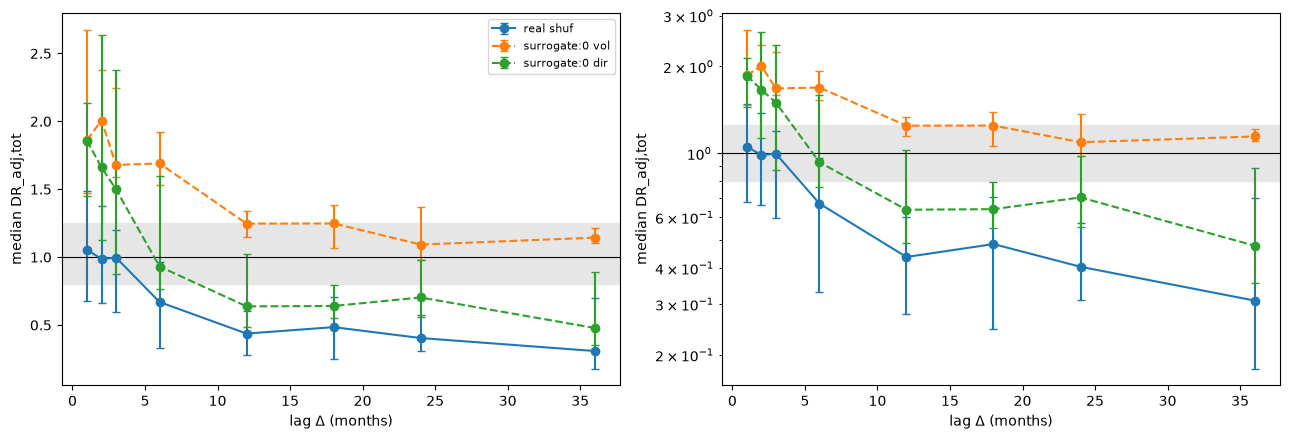

real shuf             surrogate:0 vol             surrogate:0 dir            
       median    lo    hi          median    lo    hi          median    lo    hi
lag                                                                              
1        1.05  0.68  1.49            1.86  1.47  2.67            1.86  1.45  2.13
2        0.99  0.66  1.38            2.01  1.67  2.38            1.66  1.13  2.64
3        1.00  0.60  1.20            1.68  1.59  2.24            1.50  0.87  2.38
6        0.67  0.33  0.96            1.69  1.53  1.92            0.93  0.77  1.59
12       0.44  0.28  0.60            1.25  1.15  1.34            0.64  0.49  1.03
18       0.48  0.25  0.70            1.25  1.06  1.39            0.64  0.55  0.79
24       0.40  0.31  0.57            1.09  0.98  1.37            0.70  0.56  0.98
36       0.31  0.18  0.70            1.14  1.11  1.21            0.48  0.35  0.89

Real dir and vol targets: withheld until the floor is fixed (PLAN §2, G0).


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
res = {}
for (data, target), ls in [(("real", "shuf"), "-"), (("surrogate:0", "vol"), "--"), (("surrogate:0", "dir"), "--")]:
    gm = R.gamma(pairs, data, target)
    res[(data, target)] = gm
    for ax, logy in zip(axes, (False, True)):
        ax.errorbar(gm["lag"], gm["median"], yerr=[gm["median"] - gm["lo"], gm["hi"] - gm["median"]],
                    ls=ls, marker="o", capsize=3, label=f"{data} {target}")
for ax in axes:
    ax.axhspan(0.8, 1.25, color="0.9", zorder=0)
    ax.axhline(1, color="k", lw=0.8)
    ax.set_xlabel("lag Δ (months)")
    ax.set_ylabel("median DR_adj,tot")
axes[1].set_yscale("log")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()
tab = pd.concat({f"{d} {t}": v.set_index("lag")[["median", "lo", "hi"]] for (d, t), v in res.items()}, axis=1)
display(tab.round(2))
print("Real dir and vol targets: withheld until the floor is fixed (PLAN §2, G0).")

## 5. Positive control: vol target (criterion 3)

features with median SNR > 4: 8 (need >= 3) -> True
OOS R² > 0 in 100.0% of 83 months (need >= 80%) -> True; median OOS R² 0.350


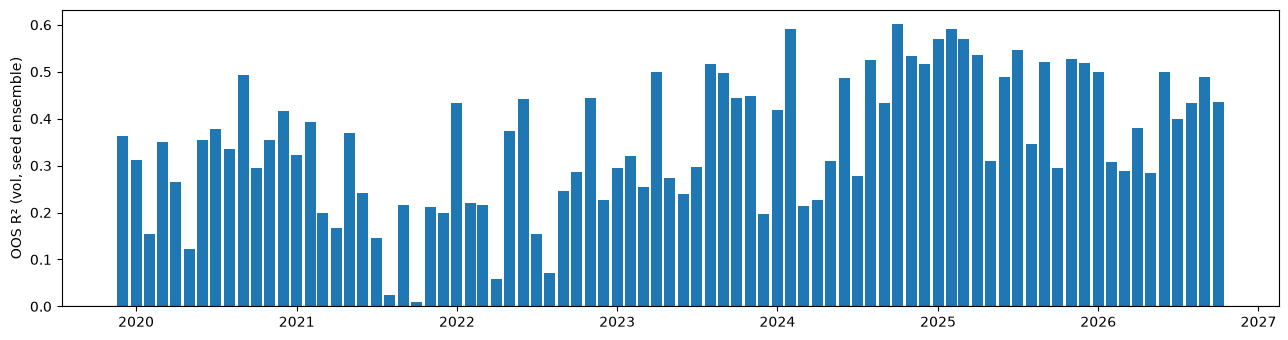

target,skill dir,skill shuf,skill vol
count,83.000,83.000,83.000
mean,0.002,-0.000,0.351
std,0.008,0.005,0.143
min,-0.024,-0.012,0.009
25%,-0.001,-0.002,0.244
50%,0.002,-0.000,0.350
75%,0.007,0.001,0.488
max,0.024,0.021,0.601


In [8]:
pc = R.positive_control(windows, wfeat)
print(f"features with median SNR > 4: {pc['n_features_snr_above']} (need >= 3) -> {pc['pass_snr']}")
print(f"OOS R² > 0 in {pc['oos_r2_positive_share']:.1%} of {pc['n_months']} months (need >= 80%) -> {pc['pass_r2']}; "
      f"median OOS R² {pc['oos_r2_median']:.3f}")
w = windows[(windows.data == "real")].pivot(index="tau", columns="target", values="skill")
fig, ax = plt.subplots(figsize=(13, 3.5))
ax.bar(pd.to_datetime(w.index), w["vol"], width=25)
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("OOS R² (vol, seed ensemble)")
plt.tight_layout()
plt.show()
display(w.describe().round(3).rename(columns=lambda c: f"skill {c}"))

## 6. Go / no-go (PLAN §13 M2)

In [9]:
crit = pd.DataFrame([
    {"criterion": "1. end-to-end run; kill/resume loses < 16 fits",
     "value": f"lost {kill['lost_fits_upper_bound']} (workers mid-fit), stale tmp {kill['stale_tmp_files']}, survivors {len(kill['surviving_processes'])}",
     "pass": kill["lost_fits_upper_bound"] < 16 and kill["stale_tmp_files"] == 0},
    {"criterion": "2. G0 on shuffled control, or DR* fallback",
     "value": f"shuffled {g['arms']['shuffled']['est']:.2f} [{g['arms']['shuffled']['lo']:.2f}, {g['arms']['shuffled']['hi']:.2f}]; fallback pass {g['fallback_pass']}",
     "pass": g["criterion2"]},
    {"criterion": "3. vol: median SNR > 4 for >= 3 features, OOS R² > 0 in >= 80% of months",
     "value": f"{pc['n_features_snr_above']} features; R² > 0 in {pc['oos_r2_positive_share']:.0%}",
     "pass": pc["pass"]},
    {"criterion": "4. wall time within 2x of the estimate (0.53 h)",
     "value": f"{wall/3600:.2f} h (ratio {wall/3600/est_h:.2f})", "pass": wall / 3600 / est_h <= 2},
])
display(crit)

,criterion,value,pass
0,1. end-to-end run; kill/resume loses < 16 fits,"lost 16 (workers mid-fit), stale tmp 0, surviv...",False
1,"2. G0 on shuffled control, or DR* fallback","shuffled 0.44 [0.28, 0.60]; fallback pass False",False
2,"3. vol: median SNR > 4 for >= 3 features, OOS ...",8 features; R² > 0 in 100%,True
3,4. wall time within 2x of the estimate (0.53 h),0.64 h (ratio 1.21),True
